# Demo 4: Goal-head ablations (necessity and sufficiency)

**Insight.** The goal heads are a causal bottleneck. Their access to the task description is enough for the LM to
implement the next sub-task, and once enough of them are knocked out, the LM loses it.

**Setup.** A task with several sub-tasks, the first ones already written. The prompt stops at the pivot `{var} =`
where the LM writes the next sub-task.

**Intervention.** From the pivot on, at every generated token:
- **Necessity.** The goal heads may attend only to the first token (an attention sink), so they read nothing from the
  prompt. Every other head works as usual.
- **Sufficiency.** The reverse: every head in layers ≥ 20 *except* the goal heads is blinded to the next sub-task's
  description. Only the goal heads can still read it.

Each ablation has a control: the same intervention on a random head set of the same size from the later half of the
model. An LM judge (Claude) checks whether the generated line implements the next sub-task.

**Paper.** §4 (Figure 4), App. H (Tables 4–6).

Needs one 80 GB GPU (Qwen2.5-Coder-32B-Instruct in bf16). The executed outputs are saved in this file.

**The setup** (schematics from the lab talk):

![Sufficiency setup: only the goal heads can attend to the prompt (green span); every other head in layers ≥ 20 is blinded.](figures/04_sufficiency.png)

*Sufficiency setup: only the goal heads can attend to the prompt (green span); every other head in layers ≥ 20 is blinded.*

![Necessity setup: the goal heads' attention is sunk to <bos>, so the prompt is invisible to them.](figures/04_necessity.png)

*Necessity setup: the goal heads' attention is sunk to <bos>, so the prompt is invisible to them.*

In [1]:
# repo root = first parent dir that contains src/
import os, sys
_d = os.getcwd()
while _d != '/' and not os.path.isdir(os.path.join(_d, 'src')):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d); os.chdir(_d)
print('repo root:', _d)

# no progress bars: keeps tqdm / HF widget outputs out of the saved notebook
os.environ['TQDM_DISABLE'] = '1'
import functools, tqdm.std, tqdm.notebook, transformers, huggingface_hub
for _c in (tqdm.std.tqdm, tqdm.notebook.tqdm):   # tqdm.notebook ignores TQDM_DISABLE, so force disable=True
    _c.__init__ = functools.partialmethod(_c.__init__, disable=True)
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()      # no generation-config warnings
huggingface_hub.utils.disable_progress_bars()

# as in the paper's figures: source red, destination green, patched run purple
from typing import Literal
ide_theme: Literal['dark', 'light'] = 'dark'
if ide_theme == 'dark':   # light shades; the task-span fill reuses the text color
    SRC_C, DST_C, PAT_C = 'salmon1', 'sea_green3', 'plum2'
    SRC_BG, DST_BG      = SRC_C, DST_C
    PIVOT_BG            = 'bright_yellow'
else:                     # the paper's colors (Figure 5)
    SRC_C, DST_C, PAT_C = '#cc0000', '#38761d', '#5b277d'
    SRC_BG, DST_BG      = '#f4cccc', '#d9ead3'
    PIVOT_BG            = '#ffe6b2'

repo root: /disk/u/arnab/Codes/Projects/goals


In [2]:
CUDA       = '7'
MODEL      = 'Qwen/Qwen2.5-Coder-32B-Instruct'
GOAL122    = 'head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_thr0.9_band25-56.json'   # the 122 goal heads
GOAL250    = 'head_sets/Qwen2.5-Coder-32B-Instruct/goal_topk/goal__lam20_top250.json'   # a broader set of 250
SPEC_ID    = 'list[int]_python_044'   # the task; next sub-task: the difference between the max and min values
SEED       = 123      # draws the random control heads
FROM_LAYER = 20       # sufficiency blinds the other heads in layers >= this

os.environ['CUDA_VISIBLE_DEVICES'] = CUDA

## Load the model
Qwen2.5-Coder-32B-Instruct, the goal heads at two budgets (122 and 250), and a random control set for each ablation.

In [3]:
import random, torch
import numpy as np
import matplotlib.pyplot as plt
from rich.console import Console
from rich.table import Table
from rich.markup import escape
from rich.text import Text

from src.models import ModelandTokenizer
from src.utils import experiment_utils
from src.tokens import prepare_input
from src.goals.head_sets import load_json_heads
from scripts.evaluation.eval_goalscope import DEFAULT_DATASET, ALL_DATATYPES, load_locked_datapoints, build_prompt, GEN_MAX_NEW_TOKENS
from scripts.evaluation.ablation_common import (
    SINK_POS, complement_heads, random_heads_like, frontier_block_positions,
    sink_generate_cached, generate_blocking_span_cached, judge_implements,
)

console = Console(width=140, highlight=False)
torch.set_grad_enabled(False)
experiment_utils.set_seed(SEED)

mt = ModelandTokenizer(model_key=MODEL, dtype=torch.bfloat16, device_map={'': 0}, attn_implementation='eager')
NL, NH = mt.n_layer, mt.n_heads
goal = {n: load_json_heads(p, NL, NH) for n, p in [(122, GOAL122), (250, GOAL250)]}

# necessity (eval_ablation_necessity.py): sink the goal heads; control = random |goal| heads from layers >= 32
nec = {}
for n, gh in goal.items():
    ctrl = random_heads_like(gh, NL // 2, NL, NH, gh, random.Random(SEED))
    nec[n] = dict(ablated=gh, control=ctrl)

# sufficiency (eval_ablation_sufficiency.py): blind everyone in layers >= 20 EXCEPT the spared set
gh = goal[122]
pool = [(l, h) for l in range(NL // 2, NL) for h in range(NH) if (l, h) not in set(map(tuple, gh))]
rand_spare = random.Random(SEED).sample(pool, len(gh))
suf = dict(ablated=complement_heads(gh, FROM_LAYER, NL, NH), control=complement_heads(rand_spare, FROM_LAYER, NL, NH),
           spared_goal=gh, spared_random=rand_spare)
print(f'{NL} layers x {NH} heads = {NL*NH} heads')
print(f'necessity: sink {len(goal[122])} / {len(goal[250])} goal heads, or as many random heads (layers >= {NL//2})')
print(f'sufficiency: blind {len(suf["ablated"])} heads (all of layers >= {FROM_LAYER} except the 122 goal heads); '
      f'control blinds {len(suf["control"])} (all except 122 random heads)')

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


64 layers x 40 heads = 2560 heads
necessity: sink 122 / 250 goal heads, or as many random heads (layers >= 32)
sufficiency: blind 1638 heads (all of layers >= 20 except the 122 goal heads); control blinds 1638 (all except 122 random heads)


## 1. The head sets
Which heads each arm touches, on the layer × head grid. Necessity sinks the colored heads; sufficiency spares the
colored heads and blinds every other head in the shaded layers (≥ 20).

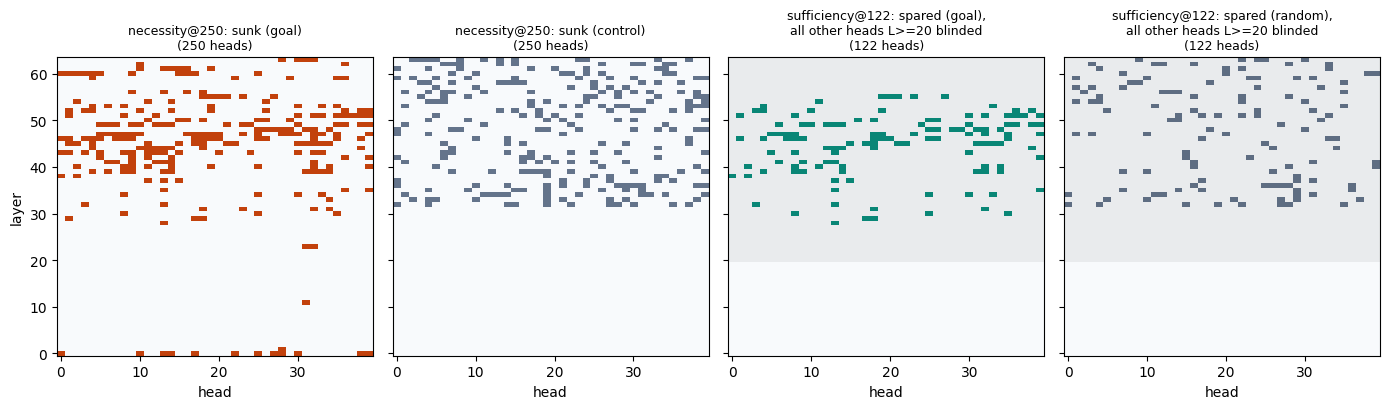

In [4]:
def grid(heads):
    M = np.zeros((NL, NH))
    for l, h in heads: M[l, h] = 1
    return M

panels = [('necessity@250: sunk (goal)', nec[250]['ablated'], '#c2410c'),
          ('necessity@250: sunk (control)', nec[250]['control'], '#64748b'),
          ('sufficiency@122: spared (goal),\nall other heads L>=20 blinded', suf['spared_goal'], '#0a8f7e'),
          ('sufficiency@122: spared (random),\nall other heads L>=20 blinded', suf['spared_random'], '#64748b')]
fig, axes = plt.subplots(1, 4, figsize=(14, 4.2), sharey=True)
from matplotlib.colors import ListedColormap
for ax, (title, hs, col) in zip(axes, panels):
    ax.imshow(grid(hs), aspect='auto', cmap=ListedColormap(['#f8fafc', col]), origin='lower', interpolation='nearest')
    if 'sufficiency' in title:
        ax.axhspan(FROM_LAYER - .5, NL - .5, color='#000', alpha=.06, lw=0)
    ax.set_title(f'{title}\n({len(hs)} heads)', fontsize=9); ax.set_xlabel('head')
axes[0].set_ylabel('layer'); fig.tight_layout(); plt.show()

## 2. The prompt
The task's sub-tasks are listed in the instruction, the first ones are already implemented, and the prompt stops at
the pivot of the next one. Highlighted: the span that the blinded heads cannot see in the sufficiency ablation (from
the next sub-task's description to the end of the prompt) and the pivot token.

In [5]:
datapoints, _ = load_locked_datapoints(DEFAULT_DATASET, ALL_DATATYPES)
inst = dict(datapoints)[SPEC_ID]
prompt, var = build_prompt(mt, inst)
cond = inst.expected_next_desc
prompt_ids = prepare_input(prompts=prompt, tokenizer=mt)['input_ids'][0].tolist()
q_start = len(prompt_ids) - 1                     # the pivot (last prompt token)
console.print(f'next sub-task: [bold]{escape(cond)}[/]  (written as `{var} = ...`)')

next sub-task: the difference between the maximum and minimum values  (written as `b = ...`)

In [6]:
block = frontier_block_positions(mt, prompt, cond)
user = prompt_ids.index(mt.tokenizer.convert_tokens_to_ids('<|im_start|>'), 1)   # start of the user turn
txt = Text()
for i in range(user, len(prompt_ids)):
    s = mt.tokenizer.decode([prompt_ids[i]])
    txt.append(s, style=f'bold black on {PIVOT_BG}' if i == q_start else f'black on {DST_BG}' if i in block else 'dim')
console.print(txt)

<|im_start|>user
Write a Python program that implements a function `func` which, given a list of integers `nums`, computes in sequential order:
(1) whether the values are sorted in non-decreasing order
(2) the difference between the maximum and minimum values
<|im_end|>
<|im_start|>assistant
<code>
def func(nums: list[int]):
    a = all(nums[i] <= nums[i+1] for i in range(len(nums)-1))
    b =

## 3. Run every arm
The clean run, then each ablation with its control. For each run we show the generated line (the prefilled
`{var} =` in grey) and the judge's verdict: **YES** if it implements the next sub-task.

In [7]:
MAX_NEW = GEN_MAX_NEW_TOKENS
first_line = lambda gen: gen.split('\n', 1)[0].strip()
stub = prompt.rsplit('\n', 1)[-1]                         # the prefilled `    {var} =`
vc = lambda v: f"[bold {'green' if v == 'YES' else 'red'}]{v}[/]"

def show_run(title, color, gen, verdict):
    console.rule(f'[bold {color}]{title}[/]')
    console.print(f'[bold]continuation:[/]\n[grey50]{escape(stub)}[/][{color}]{escape(gen.rstrip())}[/]')
    console.print(f'[bold]judge:[/] {verdict}')
    console.print()

sink  = lambda heads: sink_generate_cached(mt, prompt_ids, heads, q_start, sink_pos=SINK_POS, max_new=MAX_NEW)
blind = lambda heads: generate_blocking_span_cached(mt, prompt_ids, heads, block, q_start, max_new=MAX_NEW)
arms = {
    'clean run (no intervention)':                (DST_C, lambda: sink([])),
    'necessity: sink the 122 goal heads':         (PAT_C, lambda: sink(nec[122]['ablated'])),
    'necessity: sink 122 random heads':           (PAT_C, lambda: sink(nec[122]['control'])),
    'necessity: sink the 250 goal heads':         (PAT_C, lambda: sink(nec[250]['ablated'])),
    'necessity: sink 250 random heads':           (PAT_C, lambda: sink(nec[250]['control'])),
    'sufficiency: spare only the 122 goal heads': (PAT_C, lambda: blind(suf['ablated'])),
    'sufficiency: spare only 122 random heads':   (PAT_C, lambda: blind(suf['control'])),
}
console.print(f'next sub-task: [bold]{escape(cond)}[/]\n')
for name, (color, run) in arms.items():
    gen = run()
    show_run(name, color, gen, vc(judge_implements(first_line(gen), cond)['verdict']))

next sub-task: the difference between the maximum and minimum values

─────────────────────────────────────────────────────── clean run (no intervention) ────────────────────────────────────────────────────────

continuation:
    b = max(nums) - min(nums)

judge: YES

──────────────────────────────────────────────────── necessity: sink the 122 goal heads ────────────────────────────────────────────────────

continuation:
    b = max(nums) - min(nums)

... (12 outputs left out)

judge: YES

───────────────────────────────────────────────── sufficiency: spare only 122 random heads ─────────────────────────────────────────────────

continuation:
    b = all(nums[i] <= nums[i+1] for i in range(len(nums)-1))

judge: NO

## What to expect
<img src="figures/04_ablation_results.png" width="400" alt="Success rate under the sufficiency and necessity ablations, goal heads vs random heads (Figure 4 in the paper)">

Sparing only the goal heads should keep the next sub-task, while sparing as many random heads should lose it.
Sinking the 122 goal heads often leaves the LM on track (other heads can make up for them), but sinking the broader
250 should break it, while sinking random heads does nothing. Over 253 tasks the clean LM implements the next
sub-task 92.5% of the time. Sparing only the goal heads keeps 80.6% (122 heads) and 91.3% (250), against 10.3% and
8.7% for random heads. Sinking the goal heads gives 85.4% (122) and 15.8% (250), against 92.5% for random heads.
See §4 and Figure 4 in the paper; App. H (Tables 4 and 6) gives the exact numbers and Table 5 more examples.